# Motor Insurance Risk Modeling — Data Ingestion & Pipeline

Ingestion, pandas aggregation, and baseline portfolio audit.

> Run notebooks in order 01 → 06: later notebooks load artifacts saved by earlier ones.

In [1]:
import os
import sys
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

import logging
from pathlib import Path

import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s")
logger = logging.getLogger(__name__)


def load_config(config_path: str = "config/config.yaml") -> dict:
    with open(config_path, "r") as f:
        return yaml.safe_load(f)


def ensure_directories(config: dict) -> None:
    for key in ("raw_dir", "processed_dir", "models_dir"):
        if key in config["data"]["paths"]:
            Path(config["data"]["paths"][key]).mkdir(parents=True, exist_ok=True)


def download_fremtpl2_data(config: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    raw_freq_path = config["data"]["paths"]["raw_freq_file"]
    raw_sev_path = config["data"]["paths"]["raw_sev_file"]

    if Path(raw_freq_path).exists() and Path(raw_sev_path).exists():
        logger.info("Loading cached raw datasets from %s", config["data"]["paths"]["raw_dir"])
        df_freq = pd.read_parquet(raw_freq_path)
        df_sev = pd.read_parquet(raw_sev_path)
        # Apply the same cleaning as fresh downloads so reruns are identical
        df_freq["IDpol"] = df_freq["IDpol"].astype("int64")
        for col, dtype in [("ClaimNb", "int32"), ("Exposure", "float64"),
                           ("VehPower", "int32"), ("VehAge", "int32"),
                           ("DrivAge", "int32"), ("BonusMalus", "int32"),
                           ("Density", "int32")]:
            if col in df_freq.columns:
                df_freq[col] = df_freq[col].astype(dtype)
        for cat_col in ["Area", "VehBrand", "VehGas", "Region"]:
            if cat_col in df_freq.columns:
                df_freq[cat_col] = df_freq[cat_col].astype(str).str.replace("'", "").str.strip()
        if "IDpol" in df_sev.columns:
            df_sev["IDpol"] = df_sev["IDpol"].astype("int64")
        if "ClaimAmount" in df_sev.columns:
            df_sev["ClaimAmount"] = df_sev["ClaimAmount"].astype("float64")
        return df_freq, df_sev

    logger.info("Fetching freMTPL2freq from OpenML (ID: %s)...", config["data"]["openml"]["freq_data_id"])
    freq_data = fetch_openml(data_id=config["data"]["openml"]["freq_data_id"], as_frame=True, parser="auto")
    df_freq = freq_data.frame

    logger.info("Fetching freMTPL2sev from OpenML (ID: %s)...", config["data"]["openml"]["sev_data_id"])
    sev_data = fetch_openml(data_id=config["data"]["openml"]["sev_data_id"], as_frame=True, parser="auto")
    df_sev = sev_data.frame

    # Enforce consistent dtypes
    df_freq["IDpol"] = df_freq["IDpol"].astype("int64")
    df_freq["ClaimNb"] = df_freq["ClaimNb"].astype("int32")
    df_freq["Exposure"] = df_freq["Exposure"].astype("float64")
    df_freq["VehPower"] = df_freq["VehPower"].astype("int32")
    df_freq["VehAge"] = df_freq["VehAge"].astype("int32")
    df_freq["DrivAge"] = df_freq["DrivAge"].astype("int32")
    df_freq["BonusMalus"] = df_freq["BonusMalus"].astype("int32")
    df_freq["Density"] = df_freq["Density"].astype("int32")

    # Remove quoting artefacts from categorical columns
    for cat_col in ["Area", "VehBrand", "VehGas", "Region"]:
        df_freq[cat_col] = df_freq[cat_col].astype(str).str.replace("'", "").str.strip()

    df_sev["IDpol"] = df_sev["IDpol"].astype("int64")
    df_sev["ClaimAmount"] = df_sev["ClaimAmount"].astype("float64")

    df_freq.to_parquet(raw_freq_path, index=False)
    df_sev.to_parquet(raw_sev_path, index=False)
    logger.info("Cached raw parquet files to %s and %s", raw_freq_path, raw_sev_path)

    return df_freq, df_sev


def build_abt(config: dict, df_freq: pd.DataFrame, df_sev: pd.DataFrame) -> pd.DataFrame:
    cleaning = config.get("cleaning", {})
    max_claim_nb_cap = cleaning.get("max_claim_nb_cap", 4)
    max_exposure = cleaning.get("max_exposure", 1.0)
    min_exposure = cleaning.get("min_exposure", 0.0027397)
    large_loss_threshold = cleaning.get("large_loss_threshold", 100000.0)
    sev = df_sev[df_sev["ClaimAmount"] > 0].copy()
    sev["IsLargeLossRecord"] = sev["ClaimAmount"] >= large_loss_threshold
    total_agg = sev.groupby("IDpol").agg(
        SevRecordCount=("ClaimAmount", "size"), TotalClaimAmount=("ClaimAmount", "sum"),
        LargeLossRecordCount=("IsLargeLossRecord", "sum"),
        LargeLossAmount=("ClaimAmount", lambda x: x[sev.loc[x.index, "IsLargeLossRecord"]].sum()),
    ).reset_index()
    attr = sev[~sev["IsLargeLossRecord"]].groupby("IDpol").agg(
        AttritionalSevRecordCount=("ClaimAmount", "size"), AttritionalClaimAmount=("ClaimAmount", "sum"),
    ).reset_index()
    agg = total_agg.merge(attr, on="IDpol", how="left")
    df = df_freq[df_freq["Exposure"] > 0].copy().merge(agg, on="IDpol", how="left")
    for col in ["SevRecordCount", "LargeLossRecordCount", "AttritionalSevRecordCount"]:
        df[col] = df[col].fillna(0).astype("int64")
    for col in ["TotalClaimAmount", "LargeLossAmount", "AttritionalClaimAmount"]:
        df[col] = df[col].fillna(0.0).astype("float64")
    df["ClaimNb_Capped"] = np.minimum(df["ClaimNb"].to_numpy(), max_claim_nb_cap)
    df["AttritionalClaimNb_Capped"] = np.minimum(df["AttritionalSevRecordCount"].to_numpy(), max_claim_nb_cap)
    df["Exposure_Capped"] = np.minimum(df["Exposure"].to_numpy(), max_exposure)
    df["LogExposure"] = np.log(np.maximum(df["Exposure_Capped"].to_numpy(), min_exposure))
    df["AvgClaimSeverity"] = np.where(df["AttritionalSevRecordCount"].to_numpy() > 0,
        df["AttritionalClaimAmount"].to_numpy() / np.maximum(df["AttritionalSevRecordCount"].to_numpy(), 1), 0.0)
    df["PurePremium"] = df["AttritionalClaimAmount"] / np.maximum(df["Exposure_Capped"], 1e-9)
    df["TotalPurePremium"] = df["TotalClaimAmount"] / np.maximum(df["Exposure_Capped"], 1e-9)
    df["HasClaim"] = (df["ClaimNb"].to_numpy() > 0).astype("int64")
    df["HasAttritionalLoss"] = (df["AttritionalSevRecordCount"].to_numpy() > 0).astype("int64")
    df["IsLargeLoss"] = (df["LargeLossRecordCount"].to_numpy() > 0).astype("int64")
    df["LogDensity"] = np.log(np.maximum(df["Density"].to_numpy(), 1))
    cols = ["IDpol", "ClaimNb", "ClaimNb_Capped", "AttritionalClaimNb_Capped", "Exposure", "Exposure_Capped",
            "LogExposure", "SevRecordCount", "AttritionalSevRecordCount", "TotalClaimAmount",
            "AttritionalClaimAmount", "LargeLossAmount", "AvgClaimSeverity", "PurePremium", "TotalPurePremium",
            "HasClaim", "HasAttritionalLoss", "IsLargeLoss", "Area", "VehPower", "VehAge", "DrivAge",
            "BonusMalus", "VehBrand", "VehGas", "Density", "LogDensity", "Region"]
    df_abt = df[cols].reset_index(drop=True)
    abt_path = config["data"]["paths"]["abt_file"]
    Path(abt_path).parent.mkdir(parents=True, exist_ok=True)
    df_abt.to_parquet(abt_path, index=False)
    logger.info("Saved Analytic Base Table to %s (%d rows)", abt_path, len(df_abt))
    return df_abt


# Backwards-compatible alias (old DuckDB entry point, backend now pandas)
def build_duckdb_abt(config: dict, df_freq: pd.DataFrame, df_sev: pd.DataFrame) -> pd.DataFrame:
    import warnings
    warnings.warn("build_duckdb_abt is deprecated, use build_abt", DeprecationWarning, stacklevel=2)
    return build_abt(config, df_freq, df_sev)


def train_val_test_split(
    df: pd.DataFrame,
    test_size: float = 0.2,
    val_size: float = 0.1,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    df_trainval, df_test = train_test_split(
        df, test_size=test_size, random_state=random_state,
        stratify=df["HasClaim"],
    )
    val_fraction = val_size / (1 - test_size)
    df_train, df_val = train_test_split(
        df_trainval, test_size=val_fraction, random_state=random_state,
        stratify=df_trainval["HasClaim"],
    )
    logger.info("Split sizes — Train: %d, Val: %d, Test: %d", len(df_train), len(df_val), len(df_test))
    return df_train, df_val, df_test


def split_abt(df: pd.DataFrame, config: dict) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    split = config.get("split", {})
    seed = config.get("project", {}).get("random_seed", 42)
    return train_val_test_split(
        df,
        test_size=split.get("test_size", 0.2),
        val_size=split.get("val_size", 0.1),
        random_state=seed,
    )


def run_pipeline(config_path: str = "config/config.yaml") -> pd.DataFrame:
    config = load_config(config_path)
    ensure_directories(config)
    df_freq, df_sev = download_fremtpl2_data(config)
    df_abt = build_abt(config, df_freq, df_sev)
    return df_abt


def get_band(config, key):
    spec = config.get("bands", {}).get(key, {})
    return spec.get("bins", []), spec.get("labels", [])

## 1. Data Ingestion & Local Cache Loading

In [2]:
config = load_config("../config/config.yaml")
nb_config = {
    "data": {
        "openml": config["data"]["openml"],
        "paths": {
            "raw_dir": "../data/raw",
            "processed_dir": "../data/processed",
            "raw_freq_file": "../data/raw/freMTPL2freq.parquet",
            "raw_sev_file": "../data/raw/freMTPL2sev.parquet",
            "abt_file": "../data/processed/abt_motor_portfolio.parquet"
        }
    },
    "cleaning": config.get("cleaning", {}),
}

ensure_directories(nb_config)
df_freq, df_sev = download_fremtpl2_data(nb_config)
print(f"Frequency records loaded: {len(df_freq):,} policies")
print(f"Severity records loaded:  {len(df_sev):,} claim payouts")

2026-10-12 14:28:32,749 [INFO] Loading cached raw datasets from ../data/raw


Frequency records loaded: 678,013 policies
Severity records loaded:  26,639 claim payouts


## 2. Pandas ABT Build & Aggregation

In [3]:
df_abt = build_abt(nb_config, df_freq, df_sev)
print(f"Analytic Base Table (ABT) generated: {df_abt.shape[0]:,} rows x {df_abt.shape[1]} columns")

2026-10-12 14:28:41,390 [INFO] Saved Analytic Base Table to ../data/processed/abt_motor_portfolio.parquet (678013 rows)


Analytic Base Table (ABT) generated: 678,013 rows x 28 columns


## 3. Data Quality & Schema Validation Checks

In [4]:
df_dq = pd.DataFrame([{
    "total_policies": len(df_abt),
    "unique_policies": df_abt["IDpol"].nunique(),
    "null_idpol": int(df_abt["IDpol"].isna().sum()),
    "non_positive_exposure": int((df_abt["Exposure"] <= 0).sum()),
    "negative_claims": int((df_abt["TotalClaimAmount"] < 0).sum()),
    "invalid_driver_age": int(((df_abt["DrivAge"] < 18) | (df_abt["DrivAge"] > 100)).sum()),
    "invalid_vehicle_age": int((df_abt["VehAge"] < 0).sum()),
    "negative_claim_counts": int((df_abt["ClaimNb"] < 0).sum()),
}])
print("=== Data Quality Audit Results ===")
display(df_dq)

=== Data Quality Audit Results ===


,total_policies,unique_policies,null_idpol,non_positive_exposure,negative_claims,invalid_driver_age,invalid_vehicle_age,negative_claim_counts
0,678013,678013,0,0,0,0,0,0


## 4. Portfolio Summary & Actuarial Metrics

In [5]:
df_summary = pd.DataFrame([{
    "total_policies": len(df_abt),
    "total_exposure_years": round(float(df_abt["Exposure_Capped"].sum()), 2),
    "total_claims": int(df_abt["ClaimNb"].sum()),
    "policies_with_claims": int(df_abt["HasClaim"].sum()),
    "claim_frequency_pct": round(float(df_abt["ClaimNb"].sum() / df_abt["Exposure_Capped"].sum() * 100), 3),
    "total_losses_eur": round(float(df_abt["TotalClaimAmount"].sum()), 2),
    "empirical_pure_premium_eur": round(float(df_abt["TotalClaimAmount"].sum() / df_abt["Exposure_Capped"].sum()), 2),
}])
display(df_summary)

,total_policies,total_exposure_years,total_claims,policies_with_claims,claim_frequency_pct,total_losses_eur,empirical_pure_premium_eur
0,678013,358360.11,36102,34060,10.074,59909216.5,167.18


## 5. Segment Summaries: Driver Age & Bonus-Malus

,DrivAgeBand,PolicyCount,TotalExposure,TotalClaims,TotalLoss,FrequencyPct,PurePremiumEUR
0,18-24,30198,12488.891085,2364,11741344.21,18.93,940.14
1,25-34,140947,64572.594437,6396,9957419.91,9.91,154.21
2,35-49,252126,131168.690662,12894,18265396.59,9.83,139.25
3,50-64,181580,102152.689449,9888,13286251.41,9.68,130.06
4,65+,73162,47977.239831,4560,6658804.38,9.50,138.79


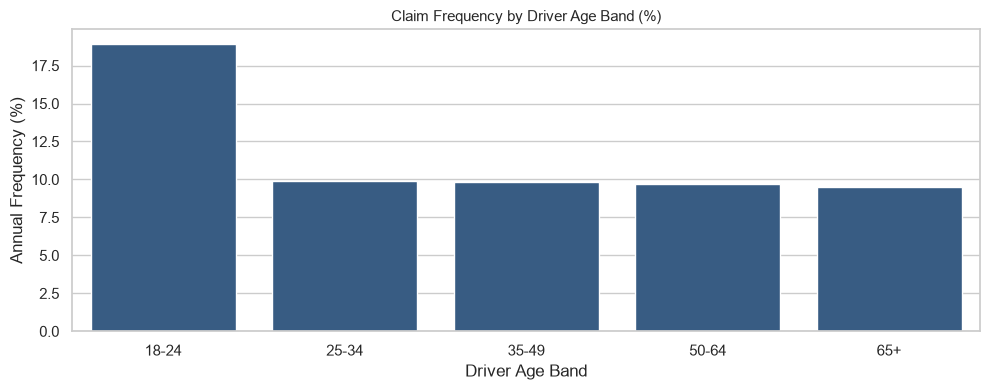

In [6]:
_age_bins, _age_labels = get_band(config, "driv_age_eda")
df_abt["DrivAgeBand"] = pd.cut(df_abt["DrivAge"], bins=_age_bins, labels=_age_labels, right=False)
df_age_summary = (
    df_abt.groupby("DrivAgeBand", observed=True)
    .agg(PolicyCount=("IDpol", "size"), TotalExposure=("Exposure_Capped", "sum"),
         TotalClaims=("ClaimNb", "sum"), TotalLoss=("TotalClaimAmount", "sum"))
    .reset_index()
)
df_age_summary["FrequencyPct"] = (df_age_summary["TotalClaims"] / df_age_summary["TotalExposure"] * 100).round(2)
df_age_summary["PurePremiumEUR"] = (df_age_summary["TotalLoss"] / df_age_summary["TotalExposure"]).round(2)
display(df_age_summary)

plt.figure(figsize=(10, 4))
sns.barplot(data=df_age_summary, x="DrivAgeBand", y="FrequencyPct", color="#2b5c8f")
plt.title("Claim Frequency by Driver Age Band (%)", fontsize=11)
plt.ylabel("Annual Frequency (%)")
plt.xlabel("Driver Age Band")
plt.tight_layout()
plt.show()

,BonusMalusGroup,Policies,TotalExposure,TotalClaims,TotalLoss,FrequencyPct,PurePremiumEUR
0,50,384156,225152.650903,18056,22282394.02,8.02,98.97
1,51-69,150262,73953.006615,8124,12976746.32,10.99,175.47
2,70-99,116271,49443.215586,6859,11903098.02,13.87,240.74
3,100,19530,6240.503357,1721,10187048.58,27.58,1632.41
4,101+,7794,3570.729003,1342,2559929.56,37.58,716.92


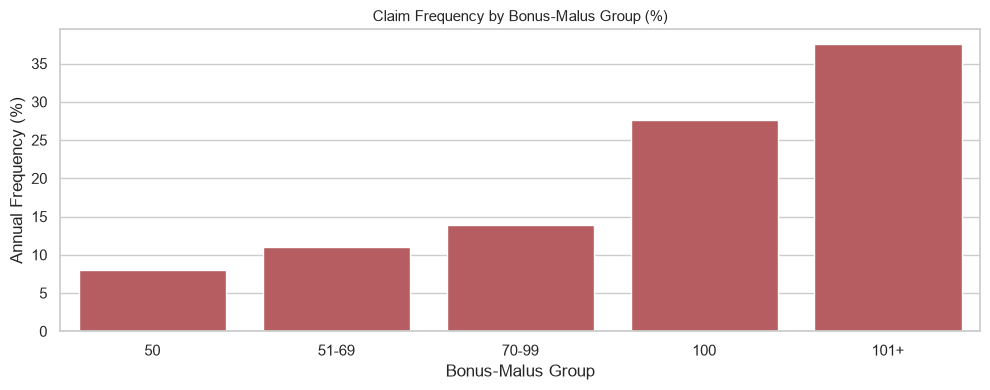

Note: the top-10 BonusMalus=100 policies hold 75.7% of that group's losses (largest €4,075,401) — attritional pricing would cap these separately.


In [7]:
_bm_bins, _bm_labels = get_band(config, "bonus_malus_eda")
df_abt["BonusMalusGroup"] = pd.cut(df_abt["BonusMalus"], bins=_bm_bins, labels=_bm_labels)
df_bm_summary = (
    df_abt.groupby("BonusMalusGroup", observed=True)
    .agg(Policies=("IDpol", "size"), TotalExposure=("Exposure_Capped", "sum"),
         TotalClaims=("ClaimNb", "sum"), TotalLoss=("TotalClaimAmount", "sum"))
    .reset_index()
)
df_bm_summary["FrequencyPct"] = (df_bm_summary["TotalClaims"] / df_bm_summary["TotalExposure"] * 100).round(2)
df_bm_summary["PurePremiumEUR"] = (df_bm_summary["TotalLoss"] / df_bm_summary["TotalExposure"]).round(2)
display(df_bm_summary)

plt.figure(figsize=(10, 4))
sns.barplot(data=df_bm_summary, x="BonusMalusGroup", y="FrequencyPct", color="#c44e52")
plt.title("Claim Frequency by Bonus-Malus Group (%)", fontsize=11)
plt.ylabel("Annual Frequency (%)")
plt.xlabel("Bonus-Malus Group")
plt.tight_layout()
plt.show()
# Mega-claim concentration check (computed live: a few huge claims can dominate a small group)
_bm100 = df_abt[df_abt["BonusMalus"] == 100].sort_values("TotalClaimAmount", ascending=False)
_top10_share = _bm100["TotalClaimAmount"].head(10).sum() / _bm100["TotalClaimAmount"].sum()
print(f"Note: the top-10 BonusMalus=100 policies hold {_top10_share:.1%} of that group's losses "
      f"(largest €{_bm100['TotalClaimAmount'].max():,.0f}) — attritional pricing would cap these separately.")